# One night, two frozen 77 M models, one question

**Is *latent* agreement a usable reference-free quality signal for MT — and does it beat the *string*
version of the same idea?**

Pre-registration: `HYPOTHESES.md`. Run log (including mistakes): `PROGRESS.md`.
This notebook only *reads* what the scripts produced; nothing here retrains or regenerates.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import pyarrow.parquet as pq
sys.path.insert(0, str(Path.cwd()))
from src import config as C

pages = pq.read_table(C.SPLIT, columns=["split"]).to_pandas()
print(pages["split"].value_counts())

split
train    3436741
test       10000
val        10000
Name: count, dtype: int64


## 1. The baseline ladder (BLEU / chrF on 10 k test, COMET on the 2 k historical core)

Every row is a *selection from the same candidate pool* (except A0, which is greedy). Numbers come
from `results/metrics_*.json` — this cell does not compute anything, it only formats.

In [2]:
from src.tables import load_all, pick
m = load_all()
rows = [{"arm": a, "BLEU": pick(e, "bleu"), "chrF": pick(e, "chrf"),
         "COMET": pick(e, "comet", ("lora_core", "core", "all", "10k", "lora"))}
        for a, e in m.items()]
df = pd.DataFrame(rows).dropna(subset=["BLEU"]).sort_values("BLEU", ascending=False).round(3)
df

,arm,BLEU,chrF,COMET
11,A5_lora_beam8,26.497,50.079,0.784
9,A9_oracle,26.231,48.756,0.792
12,A5_lora_mbr,25.809,50.395,0.783
13,A5_lora_greedy,25.660,49.065,0.774
14,A10_lp12,23.430,46.521,NaN
15,A10_lp15,23.379,46.601,NaN
3,A5_mbr_chrf,23.041,46.590,0.761
1,A1_beam,22.852,45.887,0.762
2,A3_lenratio,22.551,46.391,0.760
6,A7c_rt_lat_centred,22.323,46.002,0.761


## 2. Is the signal *usable*? Spearman vs COMET, top-1 accuracy, and headroom captured

`top-1 accuracy` = share of sentences where the utility picks the candidate that COMET likes best.
A utility can correlate well and still be useless if it always agrees on the easy sentences.

In [3]:
diag = json.load(open(C.RESULTS / "rank_diag.json", encoding="utf-8"))
ut = pd.DataFrame(diag["utilities"]).T
for k in ("learned_string", "learned_latent"):
    if k in diag:
        ut.loc[k] = [diag[k]["spearman_mean"], diag[k]["top1_acc"]]
ut

,spearman,top1_acc
chrF_bt,0.394455,0.3559
char3_bt,0.391055,0.3562
lat_cos_mean,0.249729,0.3330
lat_match_f1,0.477822,0.3696
lat_match_pre,0.465412,0.3660
lat_match_rec,0.449076,0.3541
lat_cos_mean_c,0.293283,0.3381
lat_match_f1_c,0.479710,0.3689
lat_match_pre_c,0.466948,0.3655
lat_match_rec_c,0.451732,0.3549


## 3. Does a bigger pool help? (beam-8 vs beam-8 + 8 samples, 2 k core)

`results/mixed_pool.json` and `results/metrics_mixed.json`. If the ceiling rises with candidate count,
selection was pool-limited; if it does not, selection is selector-limited.

In [4]:
mixed = json.load(open(C.RESULTS / "mixed_pool.json", encoding="utf-8"))
mx = json.load(open(C.RESULTS / "metrics_mixed.json", encoding="utf-8"))
pool_tbl = pd.DataFrame([{"pool": v["pool"], "cands/row": v["cands_per_row"],
                          "unique/row": v["unique_per_row"], "top-1 BLEU": v["bleu_top1"],
                          "oracle BLEU": v["bleu_oracle"]} for v in mixed.values()])
arm_tbl = pd.DataFrame([{"arm": k, "BLEU": round(v["bleu"], 2), "chrF": round(v["chrf"], 2)}
                        for k, v in mx.items() if isinstance(v, dict) and "bleu" in v])
print(pool_tbl.to_string(index=False))
print()
print(arm_tbl.to_string(index=False))

             pool  cands/row  unique/row  top-1 BLEU  oracle BLEU
           beam-8          8        7.96       23.32        26.54
beam-8 + sample-8         16       14.94       23.32        26.40

                   arm  BLEU  chrF
           MIX_A1_beam 23.32 46.36
       MIX_A5_mbr_chrf 23.39 46.96
         MIX_A6_rt_str 21.25 45.38
         MIX_A7_rt_lat 21.37 45.40
MIX_A7c_rt_lat_centred 21.37 45.38


## 4. Replication on a second pool (the adapted model's, 2 k / 16 k candidates)

If the latent−string gap were a quirk of one pool, it would vanish here. `results/replication.json`.

In [5]:
print(json.dumps(json.load(open(C.RESULTS / "replication.json", encoding="utf-8")), indent=2))

{
  "n_rows": 2000,
  "n_cands": 16000,
  "spearman": {
    "chrF_bt": 0.28577077881509283,
    "lat_match_f1": 0.36183579578559033,
    "lat_match_f1_c": 0.3625762858288812,
    "lat_match_pre": 0.343282509074228,
    "lat_cos_mean": 0.2318625506600312
  },
  "delta_latent_minus_string": 0.0760650169704975,
  "top1_acc": {
    "chrF_bt": 0.3735,
    "lat_match_f1": 0.3915
  }
}


## 5. The picture: latent agreement vs true quality, per candidate

One point per candidate hypothesis (sampled). If latent agreement were a clean quality signal, this
cloud would be a tight increasing band. Its shape is the answer to the research question.

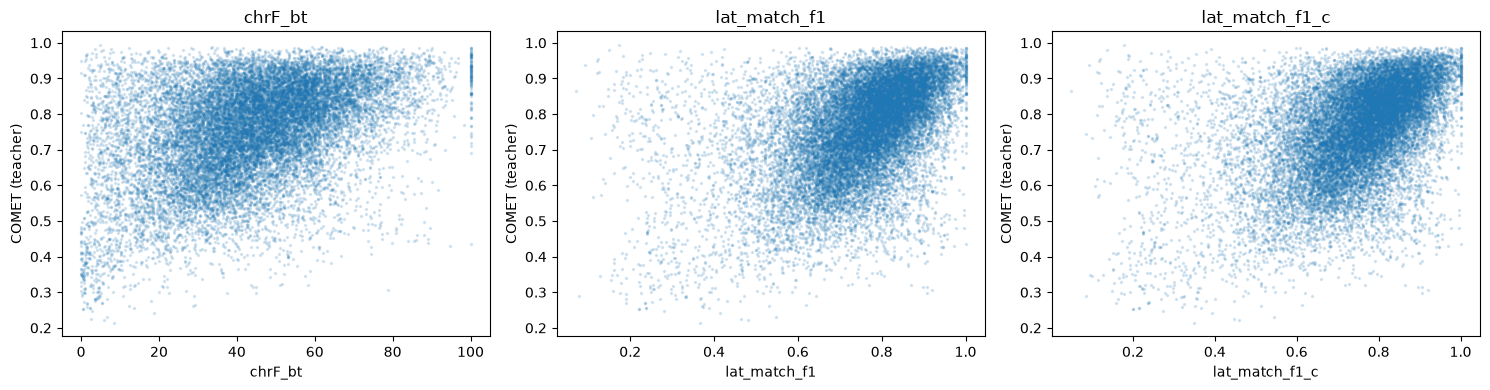

In [6]:
import matplotlib.pyplot as plt
feat = pq.read_table(C.RESULTS / "feat_test_beam8.parquet").to_pandas()
com  = pq.read_table(C.RESULTS / "comet_test_beam8.parquet").to_pandas()
df = feat.merge(com, on=["id", "rank"])
s = df.sample(min(20000, len(df)), random_state=0)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["chrF_bt", "lat_match_f1", "lat_match_f1_c"]):
    a.scatter(s[col], s["comet"], s=2, alpha=0.15)
    a.set_xlabel(col); a.set_ylabel("COMET (teacher)"); a.set_title(col)
plt.tight_layout()

## 4. What a reader should check before trusting any of this

- `results/rank_diag.json` → `n_test_rows`, `n_test_cands`: the pool size bounds everything.
- `HYPOTHESES.md` → the deviation log: what was dropped and why (`lp` was dropped, see PROGRESS).
- `PROGRESS.md` → the two self-inflicted stalls; they cost minutes, not results, but they are there.
- The LoRA control (`results/lora_control.json`, `sel_A5_lora*`) is **not** part of the claim; it
  exists so the reader can see how much of the gap is ordinary domain adaptation.